<a href="https://colab.research.google.com/github/faryalkalwar66/ML_LAB_Assignments/blob/main/week7_ML_FA26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
Name:faryal

Student ID: 023-24-0079


Section:D

GitHub:https://github.com/faryalkalwar66/ML_LAB_Assignments


**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment

**Dataset Sources:**
- Task A: Kaggle — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- Task B: Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**Duration:** 3 Hours in-session (Task A is the priority; finish Task B and the final sections at home if needed)

> This notebook is a **template**, not a tutorial. You already know Naive Bayes theory. Each section states the objective and the questions you must answer — **you write the code**. Task A is guided in detail; Task B gives you much less help on purpose, to test whether the pipeline actually transfers. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [20]:
# YOUR CODE HERE
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt
# from sklearn.model_selection import train_test_split
# from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
# from sklearn.naive_bayes import MultinomialNB
# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


---

## 1. Problem Definition & Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [22]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42

In [13]:
import os
print(os.listdir("."))

['.config', 'spam.csv', 'Tweets.csv', '.ipynb_checkpoints', 'sample_data']


In [24]:
tweets_raw = pd.read_csv("Tweets.csv")
print("Raw tweets shape:", tweets_raw.shape)
print("\nRaw class balance (incl. neutral):")
print(tweets_raw["airline_sentiment"].value_counts())


tweets = tweets_raw[["airline_sentiment", "text"]]
tweets = tweets[tweets["airline_sentiment"] != "neutral"].copy().reset_index(drop=True)
print("\nRows after dropping neutral:", tweets.shape[0])
display(tweets.head())

counts = tweets["airline_sentiment"].value_counts()
pcts = tweets["airline_sentiment"].value_counts(normalize=True) * 100
print("\nClass balance (Task B, neutral dropped):")
print(pd.DataFrame({"count": counts, "percent": pcts.round(2)}))

Raw tweets shape: (14640, 15)

Raw class balance (incl. neutral):
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

Rows after dropping neutral: 11541


,airline_sentiment,text
0,positive,@VirginAmerica plus you've added commercials t...
1,negative,@VirginAmerica it's really aggressive to blast...
2,negative,@VirginAmerica and it's a really big bad thing...
3,negative,@VirginAmerica seriously would pay $30 a fligh...
4,positive,"@VirginAmerica yes, nearly every time I fly VX..."



Class balance (Task B, neutral dropped):
                   count  percent
airline_sentiment                
negative            9178    79.53
positive            2363    20.47


**Answer 2 (Task A — spam):**
The practical problem is automatic spam filtering: given the text of an incoming SMS, the model decides whether to deliver it normally or flag/hide it as spam. It is a binary classification problem because every message belongs to exactly one of two mutually exclusive classes (spam or ham), and the model outputs a single yes/no decision.


**Answer 2 (Task B — sentiment):**
The practical problem is helping an airline monitor customer opinion at scale: automatically separating complaints (negative) from praise (positive) so that unhappy customers can be routed to support quickly and sentiment trends can be tracked per airline. After dropping the neutral tweets, each tweet is either positive or negative, so it is a binary classification problem with a single yes/no output

---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [15]:
# Task 3 — clean text
def clean_sms(s):
    s = s.str.lower()
    s = s.str.replace(r"[^a-z0-9\s]", " ", regex=True)
    s = s.str.replace(r"\s+", " ", regex=True).str.strip()
    return s

spam["clean"] = clean_sms(spam["message"])
display(spam[["message", "clean"]].head())

,message,clean
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...


In [23]:
# Task 4 — encode labels, split, fit vectorizer on train only, transform both sets
spam["y"] = (spam["label"] == "spam").astype(int)

XA_train, XA_test, yA_train, yA_test = train_test_split(
    spam["clean"], spam["y"], test_size=0.2, random_state=RANDOM_STATE, stratify=spam["y"])

vec_A = CountVectorizer()
XA_train_vec = vec_A.fit_transform(XA_train)
XA_test_vec  = vec_A.transform(XA_test)

print("Train / test sizes:", XA_train.shape[0], "/", XA_test.shape[0])
print("Spam share  train: %.3f  test: %.3f" % (yA_train.mean(), yA_test.mean()))
print("Vocabulary size (number of features):", len(vec_A.get_feature_names_out()))
print("Train matrix shape:", XA_train_vec.shape, "| Test matrix shape:", XA_test_vec.shape)

Train / test sizes: 4457 / 1115
Spam share  train: 0.134  test: 0.134
Vocabulary size (number of features): 7658
Train matrix shape: (4457, 7658) | Test matrix shape: (1115, 7658)


**Answer 4 (why fit on training data only):**
The test set must play the role of future, unseen messages. If the vectorizer is fit on the full dataset, its vocabulary would include words from the test messages, which leaks information about the test set into training and makes the evaluation optimistic (data leakage). Fitting on the training data only and then calling `transform` on the test data keeps the test set truly unseen. Words that appear only in the test set are simply ignored, just as they would be for a real new message arriving after the model is deployed.

---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

Accuracy     0.9839
Precision    0.9645
Recall       0.9128
F1-score     0.9379


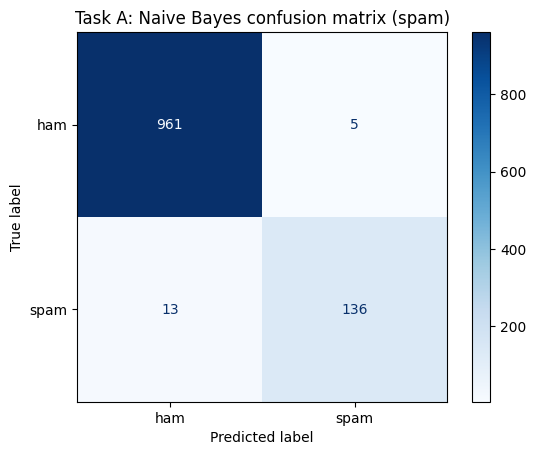

TN=961  FP=5  FN=13  TP=136


In [17]:
# Task 5 — train MultinomialNB, compute metrics, plot confusion matrix
nb_A = MultinomialNB()
nb_A.fit(XA_train_vec, yA_train)
predA = nb_A.predict(XA_test_vec)

def get_metrics(y_true, y_pred):
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall":    recall_score(y_true, y_pred),
            "F1-score":  f1_score(y_true, y_pred)}

metrics_A_nb = get_metrics(yA_test, predA)
print(pd.Series(metrics_A_nb).round(4).to_string())

cm_A = confusion_matrix(yA_test, predA)
ConfusionMatrixDisplay(cm_A, display_labels=["ham", "spam"]).plot(cmap="Blues", values_format="d")
plt.title("Task A: Naive Bayes confusion matrix (spam)")
plt.show()

tn, fp, fn, tp = cm_A.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")


**Task 5 — Spam Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 0.9839 |
| Precision |0.9645 |
| Recall |0.9128  |
| F1-score |0.9379 |

**Answer 6:**
For a spam filter, a false positive is the worse error. A false negative only means one unwanted spam message reaches the inbox, which the user can ignore or delete in a second. A false positive means a legitimate message (an OTP, a bank alert, a message from a friend or a teacher) is hidden from the user, who may never notice it, and the cost can be missed money, missed deadlines or damaged relationships. Because false positives are what hurt most, I would prioritize precision (the share of messages flagged as spam that really are spam) when tuning further, for example by raising the probability threshold required to label a message as spam, and accept a somewhat lower recall in exchange.

---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [18]:
# Task 7 — extract top spam words and top ham words from feature_log_prob_
words = vec_A.get_feature_names_out()
log_ratio = nb_A.feature_log_prob_[1] - nb_A.feature_log_prob_[0]

top_spam_idx = np.argsort(log_ratio)[::-1][:15]
top_ham_idx  = np.argsort(log_ratio)[:15]

top_words = pd.DataFrame({
    "spam word": words[top_spam_idx], "log-ratio (spam)": log_ratio[top_spam_idx].round(2),
    "ham word":  words[top_ham_idx],  "log-ratio (ham)":  log_ratio[top_ham_idx].round(2)})
display(top_words)


,spam word,log-ratio (spam),ham word,log-ratio (ham)
0,claim,5.53,gt,-4.59
1,prize,5.20,lt,-4.57
2,150p,4.98,he,-4.10
3,tone,4.83,da,-3.89
4,18,4.71,lor,-3.89
5,cs,4.67,she,-3.86
6,500,4.61,later,-3.79
7,guaranteed,4.61,ll,-3.34
8,1000,4.50,doing,-3.30
9,uk,4.44,say,-3.27


**Answer 7:**
The 15 most spam-associated words are *claim, prize, 150p, tone, 18, cs, 500, guaranteed, 1000, uk, 150ppm, awarded, www, ringtone, collection*. These match my intuition well: they are about winning something (claim, prize, awarded, guaranteed), money and premium-rate pricing (150p, 150ppm, 500, 1000), ringtone/subscription services, and web links. The "18" also makes sense because many such offers state an age restriction.

The 15 most ham-associated words are *gt, lt, he, lor, da, she, later, ll, doing, say, really, ask, home, anything, amp*. Many are everyday conversational words (he, she, later, doing, home, really), and *lor* and *da* are informal chat words typical of personal texting. What surprised me is *gt*, *lt* and *amp*: they are not real words but leftovers of HTML entities (&gt;, &lt;, &amp;) that appear in the raw SMS text of ordinary chats. The model learned them as "ham" signals purely from the data, which shows that Naive Bayes learns whatever statistics separate the classes, not necessarily meaningful words.

In [ ]:
# Task 8 — test your own messages
my_messages = [
    "Congratulations! You have won a FREE prize. Call now to claim your cash reward",
    "URGENT! Your account is suspended, txt STOP to 87121 to claim 1000 bonus",
    "Hey, are we still meeting for lunch tomorrow at 1?",
    "Can you send me the notes from class today",
    "Are you free tonight? Call me when you reach home",
]
clean_msgs = clean_sms(pd.Series(my_messages))
X_new = vec_A.transform(clean_msgs)
probs = nb_A.predict_proba(X_new)
preds = nb_A.predict(X_new)

for m, p, pr in zip(my_messages, preds, probs):
    print(f"[{'SPAM' if p == 1 else 'HAM '}]  P(spam)={pr[1]:.3f}  |  {m}")


**Answer 8:**
The two obviously spam-like messages were classified as spam and the two ordinary messages as ham, as I expected, with probabilities very close to 0 or 1 because the words involved (*claim, prize, free, urgent, 1000* vs. *meeting, lunch, class, notes*) are strongly tied to one class. I also added a tricky ham message, "Are you free tonight? Call me when you reach home", which contains the typical spam trigger words "free" and "call". The model still classified it correctly as ham, because the other words (*you, tonight, me, when, reach, home*) are strongly ham-associated and outweigh the two spam-flavoured words. So all five predictions matched my expectation. This also shows how Naive Bayes works: every word adds its own independent evidence and the evidence is multiplied together, so the model never reads "are you free tonight" as a phrase.

---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**

1.   List item
2.   List item


_(paste your published notebook link here)_

https://www.kaggle.com/code/faryalkalwar11/notebook4e9fc35a42

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [25]:
# Task 11 — clean and vectorize the sentiment data (your own approach)
def clean_tweet(s):
    s = s.str.lower()
    s = s.str.replace(r"http\S+|www\S+", " ", regex=True)
    s = s.str.replace(r"@\w+", " ", regex=True)
    s = s.str.replace(r"#", "", regex=True)
    s = s.str.replace(r"[^a-z\s]", " ", regex=True)
    s = s.str.replace(r"\s+", " ", regex=True).str.strip()
    return s

tweets["clean"] = clean_tweet(tweets["text"])
tweets["y"] = (tweets["airline_sentiment"] == "positive").astype(int)
display(tweets[["text", "clean"]].head())

XB_train, XB_test, yB_train, yB_test = train_test_split(
    tweets["clean"], tweets["y"], test_size=0.2, random_state=RANDOM_STATE, stratify=tweets["y"])

vec_B = CountVectorizer()
XB_train_vec = vec_B.fit_transform(XB_train)
XB_test_vec  = vec_B.transform(XB_test)

print("Train / test sizes:", XB_train.shape[0], "/", XB_test.shape[0])
print("Positive share  train: %.3f  test: %.3f" % (yB_train.mean(), yB_test.mean()))
print("Vocabulary size:", len(vec_B.get_feature_names_out()))

,text,clean
0,@VirginAmerica plus you've added commercials t...,plus you ve added commercials to the experienc...
1,@VirginAmerica it's really aggressive to blast...,it s really aggressive to blast obnoxious ente...
2,@VirginAmerica and it's a really big bad thing...,and it s a really big bad thing about it
3,@VirginAmerica seriously would pay $30 a fligh...,seriously would pay a flight for seats that di...
4,"@VirginAmerica yes, nearly every time I fly VX...",yes nearly every time i fly vx this ear worm w...


Train / test sizes: 9232 / 2309
Positive share  train: 0.205  test: 0.205
Vocabulary size: 8748


**Answer 12:**
Beyond lowercasing and removing punctuation (as for SMS), I removed links and @mentions and stripped the `#` from hashtags. Almost every tweet starts with an @airline handle, so mentions say which airline was addressed rather than how the customer feels, and URLs are unique strings that would just add noise features, while the word inside a hashtag can still carry sentiment, so I kept it. I also dropped digits, because in tweets they are mostly flight numbers and times, unlike the SMS data where numbers such as 150p or 1000 were strong spam signals.

---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

Accuracy     0.9060
Precision    0.8951
Recall       0.6131
F1-score     0.7277


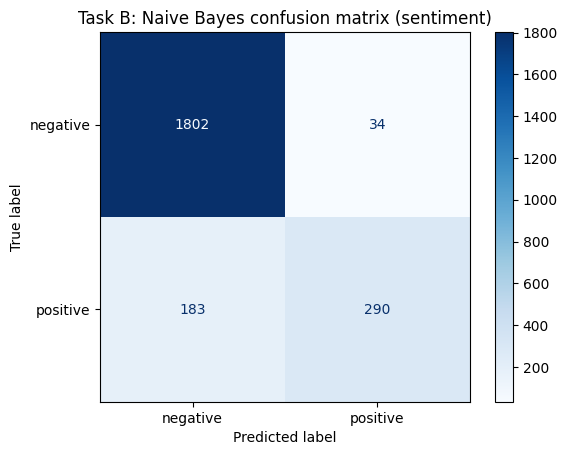

TN=1802  FP=34  FN=183  TP=290
Majority-class baseline accuracy (always 'negative'): 0.7951


In [26]:
# Task 13 — train MultinomialNB, compute metrics, plot confusion matrix
nb_B = MultinomialNB()
nb_B.fit(XB_train_vec, yB_train)
predB = nb_B.predict(XB_test_vec)

metrics_B_nb = get_metrics(yB_test, predB)
print(pd.Series(metrics_B_nb).round(4).to_string())

cm_B = confusion_matrix(yB_test, predB)
ConfusionMatrixDisplay(cm_B, display_labels=["negative", "positive"]).plot(cmap="Blues", values_format="d")
plt.title("Task B: Naive Bayes confusion matrix (sentiment)")
plt.show()

tn, fp, fn, tp = cm_B.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print("Majority-class baseline accuracy (always 'negative'): %.4f" % (1 - yB_test.mean()))


**Task 13 — Sentiment Model Metrics**

| Metric | Value |
|---|---|
| Accuracy |0.9060 |
| Precision | 0.8951|
| Recall |0.6131 |
| F1-score | 0.7277|

**Answer 14:**
Naive Bayes did worse on sentiment than on spam: F1 dropped from 0.938 to 0.728, recall from 0.913 to 0.613, and accuracy from 98.4% to 90.6%. The independence assumption is much more reasonable for spam SMS: spam is formulaic, and individual words such as *claim, prize, 150p* are strong standalone signals, so adding up per-word evidence works well. In tweets, meaning depends on word order and context: negation ("not good", "never again"), sarcasm ("great, another delay") and phrases like "thanks, but my bag is lost" mean the sentiment is not the sum of independent word votes, and a bag-of-words model cannot see that. The strong class imbalance (79.5% negative) also contributes to the low positive recall, so the gap is partly due to the data and not only to the independence assumption.

---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**
_(paste your published notebook link here)_

https://www.kaggle.com/code/faryalkalwar11/notebook46d0e8dc27

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

**Task 17 — Task A vs. Task B (Naive Bayes)**

| Metric | Task A (Spam) | Task B (Sentiment) |
|---|---|---|
| Accuracy |	0.9839 |0.9060 |
| Precision |0.9645 |0.8951 |
| Recall |0.9128 |0.6131 |
| F1-score |0.9379 |0.7277 |

In [27]:
# Task 18 — train Logistic Regression on Task A's vectorized features
lr_A = LogisticRegression(max_iter=1000)
lr_A.fit(XA_train_vec, yA_train)
predA_lr = lr_A.predict(XA_test_vec)

metrics_A_lr = get_metrics(yA_test, predA_lr)

table18 = pd.DataFrame({"Naive Bayes": metrics_A_nb,
                        "Logistic Regression": metrics_A_lr}).round(4)
display(table18)

print("Confusion matrix NB [[TN, FP], [FN, TP]]:", confusion_matrix(yA_test, predA).tolist())
print("Confusion matrix LR [[TN, FP], [FN, TP]]:", confusion_matrix(yA_test, predA_lr).tolist())


,Naive Bayes,Logistic Regression
Accuracy,0.9839,0.9812
Precision,0.9645,0.9923
Recall,0.9128,0.8658
F1-score,0.9379,0.9247


Confusion matrix NB [[TN, FP], [FN, TP]]: [[961, 5], [13, 136]]
Confusion matrix LR [[TN, FP], [FN, TP]]: [[965, 1], [20, 129]]


**Task 18 — Naive Bayes vs. Logistic Regression (Task A)**

| Metric | Naive Bayes | Logistic Regression |
|---|---|---|
| Accuracy |0.9839 |0.9812 |
| Precision |0.9645 |0.9923 |
| Recall |0.9128 |0.8658 |
| F1-score |0.9379 |0.9247 |

**Answer 18 (which wins, and does it match expectations):**
Naive Bayes wins on accuracy (0.984 vs 0.981), recall (0.913 vs 0.866) and F1 (0.938 vs 0.925), while Logistic Regression has the higher precision (0.992 vs 0.965): it made only 1 false positive compared to 5 for Naive Bayes, but missed 20 spam messages compared to 13. So there is no clear overall winner, the two are very close, and the choice depends on the cost trade-off from Answer 6: if hiding a real message is the worst error, Logistic Regression's precision is attractive. That Naive Bayes is at least as good as Logistic Regression on F1 is in line with what I expected for text: with thousands of sparse word features and only about 4,400 training messages, the independence assumption is a useful simplification that estimates each word's contribution directly from counts, whereas Logistic Regression has to learn thousands of weights jointly. A plausible explanation for its higher precision and lower recall is that it is more conservative about flagging a message as spam, but I did not test that. The small differences also come from a single train/test split, so I would not read too much into them without cross-validation

---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**
_(your answer here)_

**Answer 20 — Kaggle Notebook Links:**
- Task A: https://www.kaggle.com/code/faryalkalwar11/notebook4e9fc35a42
- Task B: https://www.kaggle.com/code/faryalkalwar11/notebook46d0e8dc27

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, both datasets)
- [ ] Section 1 — Problem Definition & Dataset Exploration (both datasets, neutral tweets dropped)
- [ ] Section 2 — Task A Cleaning & Vectorization (fit on training data only)
- [ ] Section 3 — Task A Model & Evaluation (all four metrics + confusion matrix + precision/recall argument)
- [ ] Section 4 — Task A Word Interpretation (top words + your own test messages)
- [ ] Section 5 — Task A Kaggle Notebook published and linked
- [ ] Section 6 — Task B Cleaning & Vectorization (cleaning choices justified)
- [ ] Section 7 — Task B Model & Evaluation (all four metrics + independence-assumption discussion)
- [ ] Section 8 — Task B Kaggle Notebook published and linked
- [ ] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [ ] Section 10 — Final Reflection & Conclusion (both Kaggle links listed again)
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted